# Opening-Range Breakout on WTI Crude Oil Futures

*Nova SBE, Hedge Funds (2026).*

Does an intraday opening-range breakout earn risk-adjusted returns on front-month WTI futures (CLc1) after realistic execution costs, and does it hold up out of sample?

- **Signal:** the high and low of the first 30 minutes of regular trading hours. Long on a break above the high, short on a break below the low, entering at most one hour after the range closes.
- **Exit:** a stop at 1× the opening-range width, otherwise at the close.
- **Filter:** skip days whose opening range is below the 40th percentile of past ranges (expanding window).
- **Execution:** buy at the ask, sell at the bid, plus 1bp round-trip for fees.
- **Validation:** range length and stop multiple were chosen on in-sample Sharpe (25 Mar – 31 Oct 2025); 1 Nov 2025 – 18 Mar 2026 is out of sample.

The backtest engine lives in [`quantfin/orb.py`](../src/quantfin/orb.py), the statistics in [`quantfin/performance.py`](../src/quantfin/performance.py) and the data cleaning in [`quantfin/intraday.py`](../src/quantfin/intraday.py); this notebook sets the parameters, runs them and shows the results.

The data (1-minute bid/ask bars) is licensed and not included. To run the notebook, place the export as `Clc1.csv` next to it.

In [1]:
# ── Imports ────────────────────────────────────────────────────────────────────
from __future__ import annotations

import datetime as dt
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Rectangle
from matplotlib.ticker import FuncFormatter

warnings.filterwarnings("ignore", category=FutureWarning)

from quantfin.intraday import close_to_close_returns, prepare_all_symbols, regular_hours
from quantfin.orb import (
    daily_returns_from_log,
    long_short_decomposition,
    run_orb_backtest,
    run_sweep,
)
from quantfin.performance import drawdown_series, nav_from_returns, stats_table

# ── Matplotlib / figure styling ───────────────────────────────────────────────
%config InlineBackend.figure_formats = ['svg']

A4W, A4H = 4.5, 2.8  # inches
DPI = 150

mpl.rcParams.update(
    {
        "figure.dpi": DPI,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": False,
        "font.size": 9,
        "axes.titlesize": 10,
        "axes.labelsize": 9,
        "legend.fontsize": 8,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "lines.linewidth": 1.4,
    }
)

PALETTE = ["#1f4e79", "#595959", "#1e6b3c", "#7b2d2d", "#6363c2", "#ad764d", "#2ca5a5", "#bcbc06"]

# ── Output directories ────────────────────────────────────────────────────────
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
TABLE_DIR = Path("tables")
TABLE_DIR.mkdir(exist_ok=True)


def save_fig(fig, name: str):
    fig.savefig(FIG_DIR / f"{name}.svg", bbox_inches="tight")


def save_table(df, name: str):
    df.to_csv(TABLE_DIR / f"{name}.csv")

## 1. Strategy configuration

Parameter grids for the sensitivity analysis, the baseline parameters, costs and the in-/out-of-sample split.

In [2]:
# ── CSV paths ─────────────────────────────────────────────────────────────────
CSV_PATHS = {
    "CLc1": "Clc1.csv",
}

# ── Regular-Trading-Hours (Exchange Time, ET) ─────────────────────────────────
RTH = {
    "CLC1": (dt.time(9, 0), dt.time(14, 30)),  # CL  09:00–14:30
}

# ── ORB parameters ────────────────────────────────────────────────────────────
OR_MINUTES_GRID = [5, 15, 30]  # opening-range durations
STOP_K_GRID = [0.5, 1.0, 2.0, 3.0]  # stop = k × OR range

# Range filter: skip days where OR range < Nth percentile (too tight / noisy)
RANGE_PCTILE_GRID = [0, 10, 20, 30, 40, 50, 100]  # 0 = no filter
# Time cutoff: max hours after OR close to accept a breakout entry
TIME_CUTOFF_GRID = [1, 2, 3, None]  # None = no cutoff

# Baseline parameters (selected on IS Sharpe from OR×Stop grid)
OR_MINUTES_BASE = 30
STOP_K_BASE = 1.0
RANGE_PCTILE_BASE = 40  # skip days with OR range < P40
TIME_CUTOFF_BASE = 1  # max 1 hr after OR close to enter

# ── Transaction costs ─────────────────────────────────────────────────────────
# Execution model already uses Buy@Ask / Sell@Bid (captures full spread).
# TC_RT covers only residual costs: exchange/clearing fees + commission.
# Institutional futures RT ≈ 0.5–1 bps on top of spread.
TC_RT_BPS = 1  # 1 bp round-trip (on top of bid/ask execution)
TC_RT = TC_RT_BPS / 10_000  # 0.0001
TC_BPS_GRID = [0, 1, 3, 5, 7, 10]  # sensitivity grid (bps)

# ── In-sample / out-of-sample split ──────────────────────────────────────────
IS_END = pd.Timestamp("2025-10-31")  # IS: start … 2025-10-31
OOS_START = pd.Timestamp("2025-11-01")  # OOS: 2025-11-01 … end

## 2. Data loading and cleaning

`intraday_data_prep.py` parses the raw export and flags bad bars. This step keeps regular trading hours (09:00–14:30 ET) and adds the session VWAP. Buy-and-hold uses daily close-to-close returns over the same hours.

In [3]:
data_cleaned, audit = prepare_all_symbols(paths=CSV_PATHS)
display(audit)

rth_data: dict[str, pd.DataFrame] = {}
benchmark_rets: dict[str, pd.Series] = {}  # buy-and-hold daily returns

for sym, bars in data_cleaned.items():
    rth_data[sym] = regular_hours(bars, *RTH[sym])
    n_days = rth_data[sym]["date"].nunique()
    print(
        f"{sym}: {len(rth_data[sym]):,} RTH bars across {n_days} trading days "
        f"({rth_data[sym]['datetime'].min().date()} → {rth_data[sym]['datetime'].max().date()})"
    )
    benchmark_rets[sym] = close_to_close_returns(rth_data[sym])
    print(f"  Benchmark: {len(benchmark_rets[sym])} daily returns computed")

,symbol,rows_total,rows_clean,rows_dropped,pct_retained
0,CLC1,345917,320328,25589,92.6


CLC1: 78,890 RTH bars across 254 trading days (2025-03-25 → 2026-03-18)
  Benchmark: 253 daily returns computed


## 3. Backtest engine

`run_orb_backtest` works day by day: compute the opening range, find the first breakout bar after it, then walk forward to the stop or the close. If both sides break on the same bar, the day is skipped. The stop is checked from the bar after entry, and a stopped long sells at the lower of the bid and the stop level (a short buys at the higher of the ask and the stop).

## 4. Performance metrics

`daily_returns_from_log` turns the trade log into daily returns (flat days earn zero); `stats_table` computes return, risk, drawdown and trade statistics for the in-sample, out-of-sample and full periods.

## 5. Baseline backtest

In [4]:
# ── Run baseline backtest ─────────────────────────────────────────────────────
baseline_logs: dict[str, pd.DataFrame] = {}
baseline_rets: dict[str, pd.Series] = {}
baseline_navs: dict[str, pd.Series] = {}

for sym, rth in rth_data.items():
    print(f"\n{'=' * 60}")
    print(
        f"Running ORB backtest: {sym}  |  OR={OR_MINUTES_BASE}m  "
        f"|  stop={STOP_K_BASE}×  |  range_pctile={RANGE_PCTILE_BASE}  "
        f"|  time_cutoff={TIME_CUTOFF_BASE}"
    )
    print(f"{'=' * 60}")

    log = run_orb_backtest(
        rth,
        or_minutes=OR_MINUTES_BASE,
        stop_k=STOP_K_BASE,
        range_pctile=RANGE_PCTILE_BASE,
        time_cutoff_hours=TIME_CUTOFF_BASE,
        tc_rt=TC_RT,
    )
    baseline_logs[sym] = log

    ret = daily_returns_from_log(log)
    baseline_rets[sym] = ret
    baseline_navs[sym] = nav_from_returns(ret)

    traded = log.dropna(subset=["direction"])
    n_long = (traded["direction"] == 1).sum()
    n_short = (traded["direction"] == -1).sum()
    n_flat = log["direction"].isna().sum()
    print(f"  Trades: {len(traded)} (L={n_long}, S={n_short}) | Flat days: {n_flat}")
    print(f"  Final NAV: {baseline_navs[sym].iloc[-1]:.2f}")

# ── Stats table: full period, IS, OOS — with benchmark ───────────────────────
for sym in baseline_rets:
    ret = baseline_rets[sym]
    bm = benchmark_rets[sym]

    ret_is = ret[ret.index <= IS_END]
    ret_oos = ret[ret.index >= OOS_START]
    bm_is = bm[bm.index <= IS_END]
    bm_oos = bm[bm.index >= OOS_START]

    stats_full = stats_table({f"{sym} ORB": ret, f"{sym} B&H": bm})
    stats_is = stats_table({f"{sym} ORB IS": ret_is, f"{sym} B&H IS": bm_is})
    stats_oos = stats_table({f"{sym} ORB OOS": ret_oos, f"{sym} B&H OOS": bm_oos})

    combined = pd.concat([stats_full, stats_is, stats_oos], axis=1)
    display(combined)

    save_table(stats_is, f"stats_is_{sym}")
    save_table(stats_oos, f"stats_oos_{sym}")
    save_table(combined, f"stats_combined_{sym}")


Running ORB backtest: CLC1  |  OR=30m  |  stop=1.0×  |  range_pctile=40  |  time_cutoff=1


  Trades: 146 (L=70, S=76) | Flat days: 108
  Final NAV: 129.75


,CLC1 ORB,CLC1 B&H,CLC1 ORB IS,CLC1 B&H IS,CLC1 ORB OOS,CLC1 B&H OOS
Start,2025-03-25,2025-03-26,2025-03-25,2025-03-26,2025-11-03,2025-11-03
End,2026-03-18,2026-03-18,2025-10-31,2025-10-31,2026-03-18,2026-03-18
Cumulative Return,29.75%,36.30%,20.50%,-12.69%,7.68%,56.11%
CAGR,29.49%,36.14%,34.64%,-19.57%,21.44%,221.93%
Sharpe,1.837,0.92,2.568,-0.427,1.145,2.417
Sortino,3.94,1.221,9.717,-0.507,2.269,3.44
Max Drawdown,-7.76%,-27.22%,-2.98%,-25.80%,-7.76%,-14.85%
Max DD Date,2026-03-13,2025-12-16,2025-09-29,2025-10-20,2026-03-13,2026-03-10
Longest DD (Days),85,180,42,96,79,49
Volatility (ann.),14.64%,43.96%,11.86%,35.83%,18.40%,54.45%


## 6. Figures

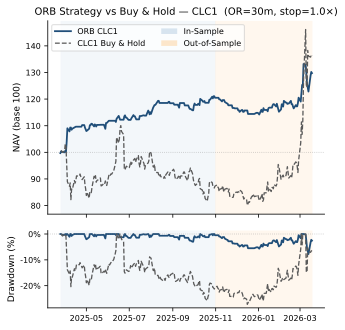

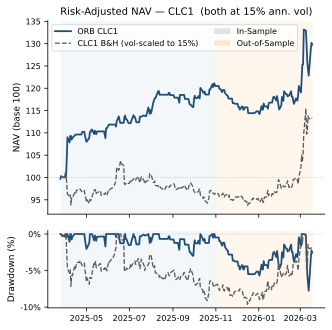

In [5]:
# ── 6.1  NAV + Drawdown ───────────────────────────────────────────────────────


def plot_nav_dd(
    navs: dict[str, pd.Series], title: str, fname: str, is_end=IS_END, oos_start=OOS_START
):
    """
    Combined NAV (top) + Drawdown (bottom) figure.
    navs: {"Label": nav_series, ...}
    """
    fig = plt.figure(figsize=(A4W, A4H * 1.6), constrained_layout=True)
    gs = GridSpec(2, 1, figure=fig, height_ratios=[2.5, 1], hspace=0.08)
    ax_nav = fig.add_subplot(gs[0])
    ax_dd = fig.add_subplot(gs[1], sharex=ax_nav)

    for i, (label, nav) in enumerate(navs.items()):
        c = PALETTE[i % len(PALETTE)]
        lw = 1.8 if i == 0 else 1.3
        ls = "-" if i == 0 else "--"
        ax_nav.plot(nav.index, nav.values, label=label, color=c, lw=lw, ls=ls)

        dd = drawdown_series(nav) * 100
        ax_dd.plot(dd.index, dd.values, color=c, lw=lw, ls=ls)

    # IS / OOS shading
    for ax in (ax_nav, ax_dd):
        ax.axvspan(pd.Timestamp(nav.index[0]), is_end, alpha=0.07, color="steelblue", zorder=0)
        ax.axvspan(oos_start, pd.Timestamp(nav.index[-1]), alpha=0.07, color="darkorange", zorder=0)

    # Add IS/OOS legend patches
    from matplotlib.patches import Patch

    is_patch = Patch(facecolor="steelblue", alpha=0.20, label="In-Sample")
    oos_patch = Patch(facecolor="darkorange", alpha=0.20, label="Out-of-Sample")

    ax_nav.axhline(100, ls=":", lw=0.8, color="grey", alpha=0.5)
    ax_nav.set_title(title, fontsize=10)
    ax_nav.set_ylabel("NAV (base 100)")
    ax_nav.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}"))
    handles, _ = ax_nav.get_legend_handles_labels()
    ax_nav.legend(handles=[*handles, is_patch, oos_patch], ncol=2, loc="upper left", framealpha=0.7)
    plt.setp(ax_nav.get_xticklabels(), visible=False)

    ax_dd.axhline(0, ls=":", lw=0.8, color="grey", alpha=0.5)
    ax_dd.set_ylabel("Drawdown (%)")
    ax_dd.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))

    save_fig(fig, fname)
    plt.show()


# Per-asset NAV + DD — with benchmark
for sym in baseline_navs:
    bm_nav = nav_from_returns(benchmark_rets[sym])
    plot_nav_dd(
        {f"ORB {sym}": baseline_navs[sym], f"{sym} Buy & Hold": bm_nav},
        title=f"ORB Strategy vs Buy & Hold — {sym}  (OR={OR_MINUTES_BASE}m, stop={STOP_K_BASE}×)",
        fname=f"nav_dd_{sym}",
    )

# ── 6.1b  Risk-Adjusted (Vol-Targeted) NAV comparison ────────────────────────
for sym in baseline_rets:
    orb_ret = baseline_rets[sym]
    bm_ret = benchmark_rets[sym]

    # Target vol = ORB strategy's realised annualised vol
    target_vol = orb_ret.std() * np.sqrt(252)
    bm_vol = bm_ret.std() * np.sqrt(252)
    scale = target_vol / bm_vol

    bm_scaled = bm_ret * scale
    nav_orb = nav_from_returns(orb_ret)
    nav_bm_sc = nav_from_returns(bm_scaled)

    plot_nav_dd(
        {f"ORB {sym}": nav_orb, f"{sym} B&H (vol-scaled to {target_vol:.0%})": nav_bm_sc},
        title=f"Risk-Adjusted NAV — {sym}  (both at {target_vol:.0%} ann. vol)",
        fname=f"nav_dd_vol_adjusted_{sym}",
    )

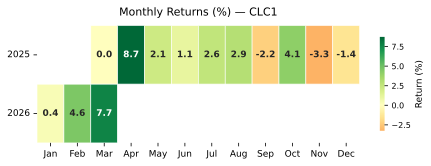

In [6]:
# ── 6.2  Monthly returns heatmap ───────────────────────────────────────────────


def plot_monthly_heatmap(ret: pd.Series, sym: str):
    monthly = (1 + ret).resample("ME").prod() - 1
    tbl = monthly.to_frame("return")
    tbl["year"] = tbl.index.year
    tbl["month"] = tbl.index.month
    pivot = tbl.pivot_table(values="return", index="year", columns="month", aggfunc="sum")
    pivot.columns = [dt.date(2000, m, 1).strftime("%b") for m in pivot.columns]

    fig, ax = plt.subplots(figsize=(A4W * 1.4, A4H * 0.85))
    sns.heatmap(
        pivot * 100,
        annot=True,
        fmt=".1f",
        center=0,
        cmap="RdYlGn",
        linewidths=0.6,
        ax=ax,
        annot_kws={"size": 9, "weight": "bold"},
        cbar_kws={"label": "Return (%)", "shrink": 0.8},
    )
    ax.set_title(f"Monthly Returns (%) — {sym}", fontsize=11, pad=10)
    ax.set_ylabel("")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0, labelsize=9)
    ax.tick_params(axis="y", rotation=0, labelsize=9)
    fig.tight_layout()
    save_fig(fig, f"monthly_returns_{sym}")
    plt.show()


for sym in baseline_rets:
    plot_monthly_heatmap(baseline_rets[sym], sym)

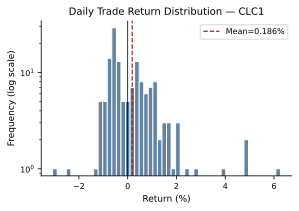

In [7]:
# ── 6.3  Daily P&L distribution ────────────────────────────────────────────────


def plot_pnl_dist(ret: pd.Series, sym: str):
    traded = ret[ret != 0]
    fig, ax = plt.subplots(figsize=(A4W, A4H))
    traded_pct = traded * 100
    ax.hist(traded_pct, bins=50, color=PALETTE[0], alpha=0.7, edgecolor="white", log=True)
    ax.axvline(
        traded_pct.mean(), color=PALETTE[3], ls="--", lw=1.2, label=f"Mean={traded_pct.mean():.3f}%"
    )
    ax.axvline(0, color="black", ls="-", lw=0.8)
    ax.set_title(f"Daily Trade Return Distribution — {sym}", fontsize=10)
    ax.set_xlabel("Return (%)")
    ax.set_ylabel("Frequency (log scale)")
    ax.legend()
    save_fig(fig, f"pnl_distribution_{sym}")
    plt.show()


for sym in baseline_rets:
    plot_pnl_dist(baseline_rets[sym], sym)

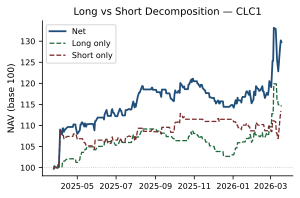

,Long,Short
# Trades,70,76
Win Rate,50.0%,44.7%
Avg Return,0.2005%,0.1721%
Total Return,14.52%,13.31%


In [8]:
# ── 6.4  Long vs Short decomposition ──────────────────────────────────────────

for sym in baseline_logs:
    ls = long_short_decomposition(baseline_logs[sym])
    nav_l = nav_from_returns(ls["Long"])
    nav_s = nav_from_returns(ls["Short"])
    nav_net = baseline_navs[sym]

    fig, ax = plt.subplots(figsize=(A4W, A4H))
    ax.plot(nav_net.index, nav_net.values, color=PALETTE[0], lw=1.8, label="Net")
    ax.plot(nav_l.index, nav_l.values, color=PALETTE[2], lw=1.3, ls="--", label="Long only")
    ax.plot(nav_s.index, nav_s.values, color=PALETTE[3], lw=1.3, ls="--", label="Short only")
    ax.axhline(100, ls=":", lw=0.8, color="grey", alpha=0.5)
    ax.set_title(f"Long vs Short Decomposition — {sym}", fontsize=10)
    ax.set_ylabel("NAV (base 100)")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}"))
    ax.legend()
    save_fig(fig, f"long_vs_short_{sym}")
    plt.show()

    # Save breakdown table
    log = baseline_logs[sym]
    traded = log.dropna(subset=["direction"])
    long_t = traded[traded["direction"] == 1]
    short_t = traded[traded["direction"] == -1]

    breakdown = pd.DataFrame(
        {
            "Long": {
                "# Trades": len(long_t),
                "Win Rate": f"{(long_t['net_return'] > 0).mean():.1%}" if len(long_t) else "N/A",
                "Avg Return": f"{long_t['net_return'].mean():.4%}" if len(long_t) else "N/A",
                "Total Return": f"{(1 + long_t['net_return']).prod() - 1:.2%}"
                if len(long_t)
                else "N/A",
            },
            "Short": {
                "# Trades": len(short_t),
                "Win Rate": f"{(short_t['net_return'] > 0).mean():.1%}" if len(short_t) else "N/A",
                "Avg Return": f"{short_t['net_return'].mean():.4%}" if len(short_t) else "N/A",
                "Total Return": f"{(1 + short_t['net_return']).prod() - 1:.2%}"
                if len(short_t)
                else "N/A",
            },
        }
    )
    display(breakdown)
    save_table(breakdown, f"long_short_breakdown_{sym}")

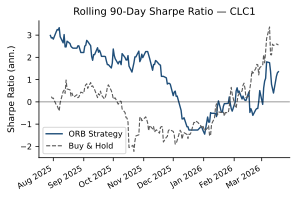

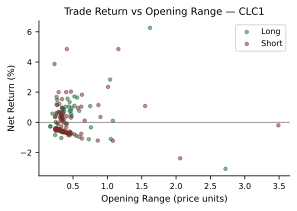

In [9]:
# ── 6.5  Rolling Sharpe (90-day) ───────────────────────────────────────────────


def plot_rolling_sharpe(
    ret: pd.Series, sym: str, window: int = 90, bm_ret: pd.Series | None = None
):
    roll_mu = ret.rolling(window).mean()
    roll_sd = ret.rolling(window).std(ddof=1)
    roll_sharpe = (roll_mu / roll_sd * np.sqrt(252)).dropna()

    fig, ax = plt.subplots(figsize=(A4W, A4H))
    ax.plot(roll_sharpe.index, roll_sharpe.values, color=PALETTE[0], lw=1.4, label="ORB Strategy")

    # Benchmark rolling Sharpe
    if bm_ret is not None:
        bm_mu = bm_ret.rolling(window).mean()
        bm_sd = bm_ret.rolling(window).std(ddof=1)
        bm_roll = (bm_mu / bm_sd * np.sqrt(252)).dropna()
        ax.plot(
            bm_roll.index, bm_roll.values, color=PALETTE[1], lw=1.1, ls="--", label="Buy & Hold"
        )

    ax.axhline(0, ls="-", lw=0.8, color="black", alpha=0.5)
    ax.set_title(f"Rolling {window}-Day Sharpe Ratio — {sym}", fontsize=10)
    ax.set_ylabel("Sharpe Ratio (ann.)")
    ax.legend()
    fig.autofmt_xdate()
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    save_fig(fig, f"rolling_sharpe_{sym}")
    plt.show()


for sym in baseline_rets:
    plot_rolling_sharpe(baseline_rets[sym], sym, bm_ret=benchmark_rets[sym])


# ── 6.6  Trade scatter: Return vs OR range ────────────────────────────────────

for sym in baseline_logs:
    traded = baseline_logs[sym].dropna(subset=["direction"]).copy()
    if traded.empty:
        continue

    fig, ax = plt.subplots(figsize=(A4W, A4H))
    longs = traded[traded["direction"] == 1]
    shorts = traded[traded["direction"] == -1]

    ax.scatter(
        longs["or_range"],
        longs["net_return"] * 100,
        s=12,
        alpha=0.5,
        color=PALETTE[2],
        label="Long",
        zorder=3,
    )
    ax.scatter(
        shorts["or_range"],
        shorts["net_return"] * 100,
        s=12,
        alpha=0.5,
        color=PALETTE[3],
        label="Short",
        zorder=3,
    )
    ax.axhline(0, ls="-", lw=0.8, color="black", alpha=0.5)
    ax.set_title(f"Trade Return vs Opening Range — {sym}", fontsize=10)
    ax.set_xlabel("Opening Range (price units)")
    ax.set_ylabel("Net Return (%)")
    ax.legend()
    save_fig(fig, f"trade_scatter_{sym}")
    plt.show()

## 7. Sensitivity analysis

Vary one parameter at a time around the baseline with `run_sweep`: range length × stop multiple (with the baseline filters), the range filter and the entry cutoff (each with the other filter switched off), and round-trip costs.

In [10]:
# ── 7.1  Sensitivity sweeps ────────────────────────────────────────────────────
# (a) OR duration × stop multiple, with the baseline filters
# (b) range percentile and (c) entry cutoff, each with the other filter off
# (d) round-trip costs at the baseline parameters

# ── (a) OR × Stop grid (with baseline filters applied) ───────────────────────
sensitivity_or_stop: dict[str, list[dict]] = {}
for sym, rth in rth_data.items():
    rows = run_sweep(
        rth,
        {
            "or_minutes": OR_MINUTES_GRID,
            "stop_k": STOP_K_GRID,
            "range_pctile": [RANGE_PCTILE_BASE],
            "time_cutoff_hours": [TIME_CUTOFF_BASE],
        },
        IS_END,
        OOS_START,
    )
    sensitivity_or_stop[sym] = rows

# ── (b) Range percentile sweep (baseline OR & stop) ──────────────────────────
sensitivity_range: dict[str, list[dict]] = {}
for sym, rth in rth_data.items():
    rows = run_sweep(
        rth,
        {
            "or_minutes": [OR_MINUTES_BASE],
            "stop_k": [STOP_K_BASE],
            "range_pctile": RANGE_PCTILE_GRID,
        },
        IS_END,
        OOS_START,
    )
    sensitivity_range[sym] = rows

# ── (c) Time cutoff sweep (baseline OR & stop) ───────────────────────────────
sensitivity_cutoff: dict[str, list[dict]] = {}
for sym, rth in rth_data.items():
    rows = run_sweep(
        rth,
        {
            "or_minutes": [OR_MINUTES_BASE],
            "stop_k": [STOP_K_BASE],
            "time_cutoff_hours": TIME_CUTOFF_GRID,
        },
        IS_END,
        OOS_START,
    )
    sensitivity_cutoff[sym] = rows

# ── (d) Transaction cost sweep (baseline params) ─────────────────────────────
sensitivity_tc: dict[str, list[dict]] = {}
for sym, rth in rth_data.items():
    rows = run_sweep(
        rth,
        {
            "or_minutes": [OR_MINUTES_BASE],
            "stop_k": [STOP_K_BASE],
            "range_pctile": [RANGE_PCTILE_BASE],
            "time_cutoff_hours": [TIME_CUTOFF_BASE],
            "tc_rt": [bps / 10_000 for bps in TC_BPS_GRID],
        },
        IS_END,
        OOS_START,
    )
    sensitivity_tc[sym] = rows

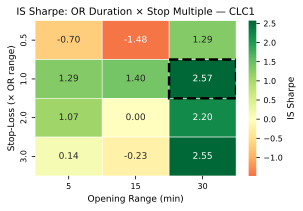

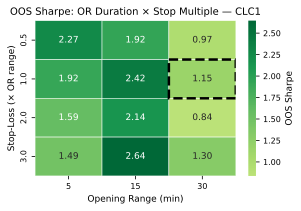

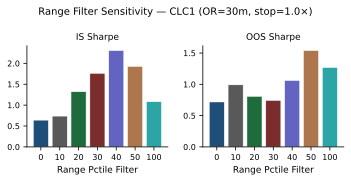

C:\Users\Jonathan\AppData\Local\Temp\ipykernel_17660\154069462.py:77: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  df_tc["time_cutoff_hours"] = df_tc["time_cutoff_hours"].fillna("None")


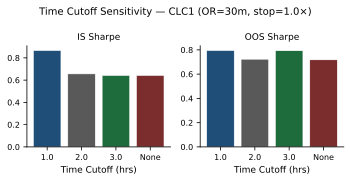

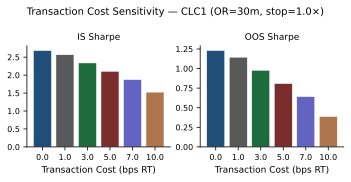

,or_minutes,stop_k,range_pctile,time_cutoff_hours,is_sharpe,oos_sharpe,full_sharpe,cum_return,max_dd,n_trades
9,30,1.0,40,1,2.568,1.145,1.837,0.297521,-0.077620,146
11,30,3.0,40,1,2.548,1.304,1.901,0.354619,-0.094395,146
10,30,2.0,40,1,2.200,0.838,1.436,0.270583,-0.158840,146
5,15,1.0,40,1,1.399,2.421,1.853,0.324100,-0.082088,155
1,5,1.0,40,1,1.293,1.916,1.558,0.228476,-0.056968,153
8,30,0.5,40,1,1.288,0.971,1.100,0.144529,-0.063327,146
2,5,2.0,40,1,1.069,1.589,1.289,0.209473,-0.104679,153
3,5,3.0,40,1,0.144,1.487,0.812,0.138015,-0.107128,153
6,15,2.0,40,1,0.004,2.141,1.056,0.190550,-0.132307,155
7,15,3.0,40,1,-0.226,2.644,1.173,0.231439,-0.153096,155


In [11]:
# ── 7.2  Sensitivity heatmaps & tables ─────────────────────────────────────────

for sym in sensitivity_or_stop:
    # ── (a) OR × Stop heatmaps (IS & OOS) ────────────────────────────────────
    df_os = pd.DataFrame(sensitivity_or_stop[sym])

    pivot_is = df_os.pivot_table(
        values="is_sharpe", index="stop_k", columns="or_minutes", aggfunc="mean"
    )
    pivot_oos = df_os.pivot_table(
        values="oos_sharpe", index="stop_k", columns="or_minutes", aggfunc="mean"
    )

    for pivot, metric_label, fname_suffix in [
        (pivot_is, "IS Sharpe", "sensitivity_or_x_stop"),
        (pivot_oos, "OOS Sharpe", "sensitivity_or_x_stop_oos"),
    ]:
        fig, ax = plt.subplots(figsize=(A4W, A4H))
        ax.grid(False)
        sns.heatmap(
            pivot,
            annot=True,
            fmt=".2f",
            center=0,
            cmap="RdYlGn",
            linewidths=0.5,
            ax=ax,
            cbar_kws={"label": metric_label},
        )

        # Highlight baseline cell
        if STOP_K_BASE in pivot.index and OR_MINUTES_BASE in pivot.columns:
            base_row = list(pivot.index).index(STOP_K_BASE)
            base_col = list(pivot.columns).index(OR_MINUTES_BASE)
            ax.add_patch(
                Rectangle(
                    (base_col, base_row), 1, 1, fill=False, edgecolor="black", lw=2.5, ls="--"
                )
            )

        ax.set_title(f"{metric_label}: OR Duration × Stop Multiple — {sym}", fontsize=10)
        ax.set_xlabel("Opening Range (min)")
        ax.set_ylabel("Stop-Loss (× OR range)")
        save_fig(fig, f"{fname_suffix}_{sym}")
        save_table(pivot, f"{fname_suffix}_{sym}")
        plt.show()

    # ── (b) Range percentile impact bar chart ─────────────────────────────────
    df_rng = pd.DataFrame(sensitivity_range[sym])
    fig, axes = plt.subplots(1, 2, figsize=(A4W * 1.1, A4H * 0.9))

    for ax, col, label in zip(
        axes, ["is_sharpe", "oos_sharpe"], ["IS Sharpe", "OOS Sharpe"], strict=True
    ):
        vals = df_rng.set_index("range_pctile")[col]
        ax.bar(
            vals.index.astype(str),
            vals.values,
            color=PALETTE[: len(vals)],
            edgecolor="white",
            linewidth=0.5,
        )
        ax.grid(False)
        ax.set_title(label, fontsize=9)
        ax.set_xlabel("Range Pctile Filter")
    fig.suptitle(
        f"Range Filter Sensitivity — {sym} (OR={OR_MINUTES_BASE}m, stop={STOP_K_BASE}×)",
        fontsize=10,
    )
    fig.tight_layout()
    save_fig(fig, f"sensitivity_range_pctile_{sym}")
    save_table(df_rng, f"sensitivity_range_pctile_{sym}")
    plt.show()

    # ── (c) Time cutoff impact bar chart ──────────────────────────────────────
    df_tc = pd.DataFrame(sensitivity_cutoff[sym])
    df_tc["time_cutoff_hours"] = df_tc["time_cutoff_hours"].fillna("None")
    fig, axes = plt.subplots(1, 2, figsize=(A4W * 1.1, A4H * 0.9))

    for ax, col, label in zip(
        axes, ["is_sharpe", "oos_sharpe"], ["IS Sharpe", "OOS Sharpe"], strict=True
    ):
        vals = df_tc.set_index("time_cutoff_hours")[col]
        ax.bar(
            [str(v) for v in vals.index],
            vals.values,
            color=PALETTE[: len(vals)],
            edgecolor="white",
            linewidth=0.5,
        )
        ax.grid(False)
        ax.set_title(label, fontsize=9)
        ax.set_xlabel("Time Cutoff (hrs)")
    fig.suptitle(
        f"Time Cutoff Sensitivity — {sym} (OR={OR_MINUTES_BASE}m, stop={STOP_K_BASE}×)", fontsize=10
    )
    fig.tight_layout()
    save_fig(fig, f"sensitivity_time_cutoff_{sym}")
    save_table(df_tc, f"sensitivity_time_cutoff_{sym}")
    plt.show()

    # ── (d) Transaction cost impact bar chart ─────────────────────────────────
    df_sens = pd.DataFrame(sensitivity_tc[sym])
    df_sens["tc_bps"] = (df_sens["tc_rt"] * 10_000).round(1)
    fig, axes = plt.subplots(1, 2, figsize=(A4W * 1.1, A4H * 0.9))

    for ax, col, label in zip(
        axes, ["is_sharpe", "oos_sharpe"], ["IS Sharpe", "OOS Sharpe"], strict=True
    ):
        vals = df_sens.set_index("tc_bps")[col]
        ax.bar(
            vals.index.astype(str),
            vals.values,
            color=PALETTE[: len(vals)],
            edgecolor="white",
            linewidth=0.5,
        )
        ax.grid(False)
        ax.set_title(label, fontsize=9)
        ax.set_xlabel("Transaction Cost (bps RT)")
    fig.suptitle(
        f"Transaction Cost Sensitivity — {sym} (OR={OR_MINUTES_BASE}m, stop={STOP_K_BASE}×)",
        fontsize=10,
    )
    fig.tight_layout()
    save_fig(fig, f"sensitivity_tc_{sym}")
    save_table(df_sens, f"sensitivity_tc_{sym}")
    plt.show()

    # ── Full sensitivity table (OR × Stop) ────────────────────────────────────
    save_table(df_os, f"sensitivity_full_{sym}")
    display(df_os.sort_values("is_sharpe", ascending=False).head(10))

## 8. Trade log and position summary

In [12]:
# ── Trade log export & position summary ────────────────────────────────────────

for sym in baseline_logs:
    log = baseline_logs[sym]
    traded = log.dropna(subset=["direction"]).copy()

    # Save full trade log
    save_table(traded, f"trade_log_{sym}")
    print(f"{sym}: {len(traded)} trades saved to tables/trade_log_{sym}.csv")
    display(traded.head(10))

    # ── Position summary ──────────────────────────────────────────────────────
    total_days = log["date"].nunique()
    traded_days = len(traded)
    n_long = (traded["direction"] == 1).sum()
    n_short = (traded["direction"] == -1).sum()
    n_stop = (traded["exit_reason"] == "STOP").sum()
    n_moc = (traded["exit_reason"] == "MOC").sum()

    # Holding time in minutes
    if "entry_time" in traded.columns and "exit_time" in traded.columns:
        hold_min = (
            pd.to_datetime(traded["exit_time"]) - pd.to_datetime(traded["entry_time"])
        ).dt.total_seconds() / 60
        avg_hold = hold_min.mean()
        med_hold = hold_min.median()
    else:
        avg_hold = med_hold = np.nan

    # Monthly trade count
    traded["_month"] = pd.to_datetime(traded["date"]).dt.to_period("M")
    monthly_trades = traded.groupby("_month").size()

    summary = pd.DataFrame(
        {
            sym: {
                "Total Trading Days": total_days,
                "Days Traded": traded_days,
                "% Days Traded": f"{traded_days / total_days:.1%}" if total_days else "N/A",
                "# Long Trades": n_long,
                "# Short Trades": n_short,
                "# Stopped Out": n_stop,
                "# MOC Exit": n_moc,
                "Stop-Out Rate": f"{n_stop / traded_days:.1%}" if traded_days else "N/A",
                "Avg Holding (min)": f"{avg_hold:.0f}" if not np.isnan(avg_hold) else "N/A",
                "Median Holding (min)": f"{med_hold:.0f}" if not np.isnan(med_hold) else "N/A",
                "Avg Trades / Month": f"{monthly_trades.mean():.1f}",
                "Avg OR Range": f"{traded['or_range'].mean():.4f}",
            }
        }
    )
    display(summary)
    save_table(summary, f"positions_summary_{sym}")

    # ── Monthly return series export ──────────────────────────────────────────
    ret = baseline_rets[sym]
    monthly_ret = (1 + ret).resample("ME").prod() - 1
    monthly_ret.name = "monthly_return"
    save_table(monthly_ret.to_frame(), f"monthly_returns_{sym}")

CLC1: 146 trades saved to tables/trade_log_CLC1.csv


,date,direction,entry_time,entry_price,exit_time,exit_price,exit_reason,or_range,or_high,or_low,gross_return,tc,net_return,or_minutes,stop_k,range_pctile,time_cutoff
0,2025-03-25,1.0,2025-03-25 09:43:00,69.54,2025-03-25 14:19:00,69.35,STOP,0.17,69.53,69.36,-0.002732,0.0001,-0.002832,30,1.0,40,1
1,2025-03-26,1.0,2025-03-26 09:50:00,69.49,2025-03-26 14:30:00,69.93,MOC,0.26,69.46,69.20,0.006332,0.0001,0.006232,30,1.0,40,1
2,2025-03-27,1.0,2025-03-27 09:33:00,69.48,2025-03-27 09:58:00,69.31,STOP,0.17,69.50,69.33,-0.002447,0.0001,-0.002547,30,1.0,40,1
4,2025-03-31,-1.0,2025-03-31 09:32:00,69.77,2025-03-31 14:30:00,69.82,MOC,0.41,70.14,69.73,-0.000717,0.0001,-0.000817,30,1.0,40,1
5,2025-04-01,1.0,2025-04-01 09:42:00,71.28,2025-04-01 14:30:00,71.70,MOC,0.20,71.32,71.12,0.005892,0.0001,0.005792,30,1.0,40,1
6,2025-04-02,1.0,2025-04-02 09:32:00,71.06,2025-04-02 11:48:00,70.73,STOP,0.32,71.04,70.72,-0.004644,0.0001,-0.004744,30,1.0,40,1
7,2025-04-03,-1.0,2025-04-03 09:40:00,69.35,2025-04-03 14:30:00,66.66,MOC,0.23,69.59,69.36,0.038789,0.0001,0.038689,30,1.0,40,1
8,2025-04-04,-1.0,2025-04-04 09:31:00,64.93,2025-04-04 14:30:00,61.77,MOC,0.41,65.39,64.98,0.048668,0.0001,0.048568,30,1.0,40,1
9,2025-04-07,-1.0,2025-04-07 09:43:00,59.48,2025-04-07 11:15:00,60.11,STOP,0.63,60.09,59.46,-0.010592,0.0001,-0.010692,30,1.0,40,1
10,2025-04-08,1.0,2025-04-08 09:30:00,60.64,2025-04-08 14:30:00,61.46,MOC,0.45,60.69,60.24,0.013522,0.0001,0.013422,30,1.0,40,1


,CLC1
Total Trading Days,254
Days Traded,146
% Days Traded,57.5%
# Long Trades,70
# Short Trades,76
# Stopped Out,66
# MOC Exit,80
Stop-Out Rate,45.2%
Avg Holding (min),198
Median Holding (min),262
